# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser
**Scenario.** An extension officer compares rainfall regimes in Kampala, Gulu and Mbarara and advises farmers on which crop to plant when.
Monthly rainfall (mm) is **illustrative** data from the brief.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import Markdown, display
from scipy.spatial.distance import cosine
from src.rainfall import *

pd.set_option("display.float_format", "{:,.3f}".format)
regions = [Region(n, v) for n, v in RAINFALL_DATA.items()]
names = [r.name for r in regions]

## Task 1: the `Region` class

In [2]:
summary = pd.DataFrame({r.name: {"annual total (mm)": r.annual_total(), "mean month (mm)": r.mean(),
                                  "wettest month": r.wettest_month(), "driest month": r.driest_month(),
                                  "CV": r.cv()} for r in regions}).T
display(summary)

,annual total (mm),mean month (mm),wettest month,driest month,CV
Kampala,"1,600.000",133.333,May,Sep,0.372
Gulu,"1,388.000",115.667,Aug,Jan,0.614
Mbarara,"1,040.000",86.667,Apr,Jul,0.425


## Task 2: `CropRule` and monthly classification
Each crop has a suitable monthly rainfall range; a month is *Good*, *Drought risk* (below) or *Waterlogging risk* (above).
Thresholds are derived from published figures (see each rule's `source`):
* **Maize**: FAO gives 500-800 mm per growing period; with an assumed 4-month season that is **125-200 mm/month**.
* **Beans**: FAO gives 300-500 mm per growing period; with an assumed 3-month season, **100-167 mm/month**.
* **Coffee (robusta)**: UCDA gives 1,200-1,800 mm a year, well distributed over about 9 months: lower bound 1,200/12 = 100 mm, upper bound 1,800/9 = **200 mm/month**.

*Sources:* FAO, "Water and soil requirements", Table 2, https://www.fao.org/3/u3160e/u3160e04.htm ; Uganda Coffee Development Authority coffee handbook, section 2.4, https://www.ugandacoffee.go.ug/file-download/download/public/42 .
**Assumptions to be aware of:** season lengths (4 and 3 months) and treating the upper bound as a waterlogging threshold are mine, not the sources'. The sources give *water needs*, not a monthly rainfall tolerance.

In [3]:
rules = default_crop_rules()
display(pd.DataFrame([{"crop": r.crop, "low (mm/month)": r.low_mm, "high (mm/month)": r.high_mm, "source": r.source} for r in rules]).set_index("crop"))

status = {r.name: {rule.crop: rule.classify_region(r) for rule in rules} for r in regions}
for r in regions:
    df = pd.DataFrame(status[r.name], index=MONTHS)
    df.insert(0, "rain (mm)", r.rainfall)
    df["summary"] = month_labels(r, rules)
    print("\n" + r.name); display(df.T)

,low (mm/month),high (mm/month),source
crop,,,
maize,125.000,200.000,"FAO, 'Water and soil requirements', Table 2 (h..."
beans,100.000,166.667,"FAO, 'Water and soil requirements', Table 2 (h..."
coffee,100.000,200.000,"UCDA coffee handbook, s.2.4 (https://www.ugand..."



Kampala


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rain (mm),120.000,140.000,180.000,200.000,220.000,180.000,90.000,70.000,60.000,100.000,110.000,130.000
maize,Drought risk,Good,Good,Good,Waterlogging risk,Good,Drought risk,Drought risk,Drought risk,Drought risk,Drought risk,Good
beans,Good,Good,Waterlogging risk,Waterlogging risk,Waterlogging risk,Waterlogging risk,Drought risk,Drought risk,Drought risk,Good,Good,Good
coffee,Good,Good,Good,Good,Waterlogging risk,Good,Drought risk,Drought risk,Drought risk,Good,Good,Good
summary,"Good for beans, coffee","Good for maize, beans, coffee","Good for maize, coffee","Good for maize, coffee",Waterlogging risk,"Good for maize, coffee",Drought risk,Drought risk,Drought risk,"Good for beans, coffee","Good for beans, coffee","Good for maize, beans, coffee"



Gulu


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rain (mm),8.000,25.000,75.000,160.000,190.000,145.000,170.000,215.000,175.000,150.000,60.000,15.000
maize,Drought risk,Drought risk,Drought risk,Good,Good,Good,Good,Waterlogging risk,Good,Good,Drought risk,Drought risk
beans,Drought risk,Drought risk,Drought risk,Good,Waterlogging risk,Good,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good,Drought risk,Drought risk
coffee,Drought risk,Drought risk,Drought risk,Good,Good,Good,Good,Waterlogging risk,Good,Good,Drought risk,Drought risk
summary,Drought risk,Drought risk,Drought risk,"Good for maize, beans, coffee","Good for maize, coffee","Good for maize, beans, coffee","Good for maize, coffee",Waterlogging risk,"Good for maize, coffee","Good for maize, beans, coffee",Drought risk,Drought risk



Mbarara


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
rain (mm),70.000,85.000,120.000,140.000,90.000,25.000,20.000,55.000,100.000,125.000,120.000,90.000
maize,Drought risk,Drought risk,Drought risk,Good,Drought risk,Drought risk,Drought risk,Drought risk,Drought risk,Good,Drought risk,Drought risk
beans,Drought risk,Drought risk,Good,Good,Drought risk,Drought risk,Drought risk,Drought risk,Good,Good,Good,Drought risk
coffee,Drought risk,Drought risk,Good,Good,Drought risk,Drought risk,Drought risk,Drought risk,Good,Good,Good,Drought risk
summary,Drought risk,Drought risk,"Good for beans, coffee","Good for maize, beans, coffee",Drought risk,Drought risk,Drought risk,Drought risk,"Good for beans, coffee","Good for maize, beans, coffee","Good for beans, coffee",Drought risk


## Task 3: cosine similarity done properly
The earlier method used `math.cos()`, which returns the cosine of an *angle in radians*, a single number's trigonometric function, and says nothing about how similar two *vectors* are. Cosine similarity is `(a . b) / (|a| |b|)`: the cosine of the angle **between** the two vectors.

In [4]:
for a, b in [(0, 1), (0, 2), (1, 2)]:
    mine = cosine_similarity(regions[a].rainfall, regions[b].rainfall)
    ref = 1 - cosine(regions[a].rainfall, regions[b].rainfall)   # scipy returns the cosine DISTANCE
    print(f"{names[a]:8s} vs {names[b]:8s}: mine = {mine:.6f}   1 - scipy.cosine = {ref:.6f}   match = {np.isclose(mine, ref)}")

Kampala  vs Gulu    : mine = 0.786609   1 - scipy.cosine = 0.786609   match = True
Kampala  vs Mbarara : mine = 0.891250   1 - scipy.cosine = 0.891250   match = True
Gulu     vs Mbarara : mine = 0.748678   1 - scipy.cosine = 0.748678   match = True


## Task 4: three similarity / distance matrices
Cosine similarity compares only the **direction** (shape) of the two monthly profiles, not their size. Scaling a vector by any positive factor leaves its cosine similarity unchanged, so a region with twice the rain can still score 1.0. Because rainfall is never negative, all rainfall vectors point into the same corner of space, so cosine scores are inflated (typically 0.7-1.0) even for different seasonal patterns. Pearson correlation removes the mean (compares ups and downs), and Euclidean distance reflects magnitude.

In [5]:
def show(func, title):
    m = pd.DataFrame(pairwise_matrix(regions, func), index=names, columns=names)
    print(title); display(m)

show(cosine_similarity, "Cosine similarity")
show(pearson, "Pearson correlation")
show(euclidean, "Euclidean distance (mm)")

demo = regions[0].rainfall
print("Demo: Kampala vs 3x Kampala ->", "cosine =", round(cosine_similarity(demo, 3 * demo), 3),
      "| Pearson =", round(pearson(demo, 3 * demo), 3), "| Euclidean =", round(euclidean(demo, 3 * demo), 1), "mm")

Cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


Demo: Kampala vs 3x Kampala -> cosine = 1.0 | Pearson = 1.0 | Euclidean = 985.5 mm


## Task 5: rainy seasons with `scipy.signal.find_peaks`
The year is treated as a circle (a season can straddle Dec/Jan), and a peak counts as a rainy season only if its **prominence** (how far it stands above the surrounding troughs) is at least 25 % of the wettest month. That threshold is a judgement call, so the table below shows how the answer changes with it.

In [6]:
rows = []
for r in regions:
    rows.append({"region": r.name, "rainy-season peaks": ", ".join(detect_rainy_seasons(r)), "regime": rainfall_regime(r)})
display(pd.DataFrame(rows).set_index("region"))

thr = [0.02, 0.05, 0.10, 0.25, 0.35]
sens = pd.DataFrame({f"{int(t*100)}%": {r.name: " + ".join(detect_rainy_seasons(r, t)) for r in regions} for t in thr})
sens.columns.name = "min prominence (% of wettest month)"
display(sens)

,rainy-season peaks,regime
region,,
Kampala,May,unimodal
Gulu,Aug,unimodal
Mbarara,"Apr, Oct",bimodal


min prominence (% of wettest month),2%,5%,10%,25%,35%
Kampala,May + Dec,May,May,May,May
Gulu,May + Aug,May + Aug,May + Aug,Aug,Aug
Mbarara,Apr + Oct,Apr + Oct,Apr + Oct,Apr + Oct,Apr + Oct


**Check against known climate zones.** As I understand the standard description of Uganda's climate (verify against UNMA before relying on it), the southwest (Mbarara) and the Lake Victoria basin (Kampala) have **two** rainy seasons (roughly Mar-May and Sep-Nov), while the north (Gulu) has mainly one long season from about April to October. My results: **Mbarara is bimodal** (Apr, Oct), matching. **Gulu is unimodal** at the default threshold (Aug), broadly matching, though it splits into May + Aug at 15 % or less because of the Jun dip. **Kampala comes out unimodal** (May), which does *not* match: the illustrative series has a dominant Mar-May peak but only a faint Dec shoulder (about 10 mm of prominence), so it only registers as bimodal at a threshold under about 5 %. This is a limitation of the illustrative data, not evidence that Kampala has one season.

## Task 6a: all regions on one line chart (detected rainy-season peaks starred)

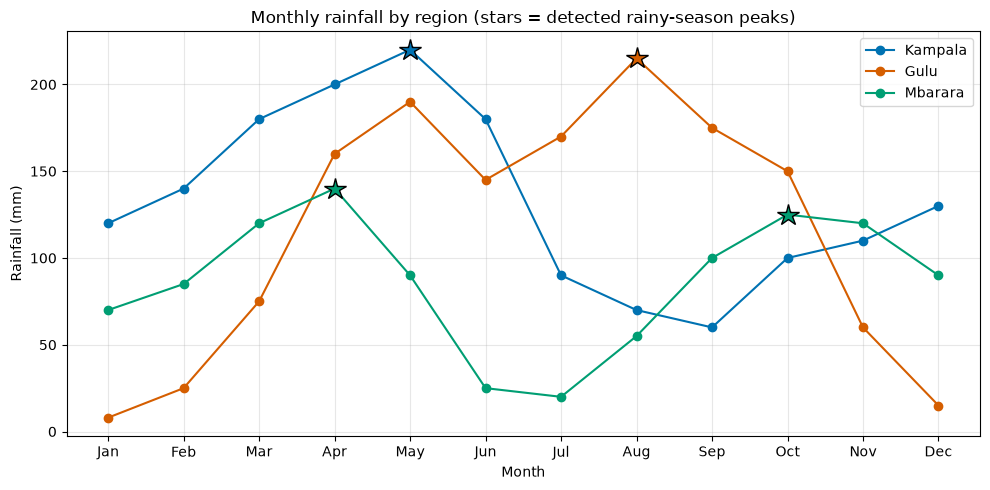

In [7]:
colors = {"Kampala": "#0072B2", "Gulu": "#D55E00", "Mbarara": "#009E73"}
fig, ax = plt.subplots(figsize=(10, 5))
for r in regions:
    ax.plot(MONTHS, r.rainfall, "o-", color=colors[r.name], label=r.name)
    for m in detect_rainy_seasons(r):
        i = MONTHS.index(m)
        ax.plot(m, r.rainfall[i], "*", ms=16, color=colors[r.name], mec="k")
ax.set_xlabel("Month"); ax.set_ylabel("Rainfall (mm)")
ax.set_title("Monthly rainfall by region (stars = detected rainy-season peaks)")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig("../figures/p4_rainfall_lines.png", dpi=150); plt.show()

## Task 6b: crop-suitability heatmap (cells show rainfall in mm)

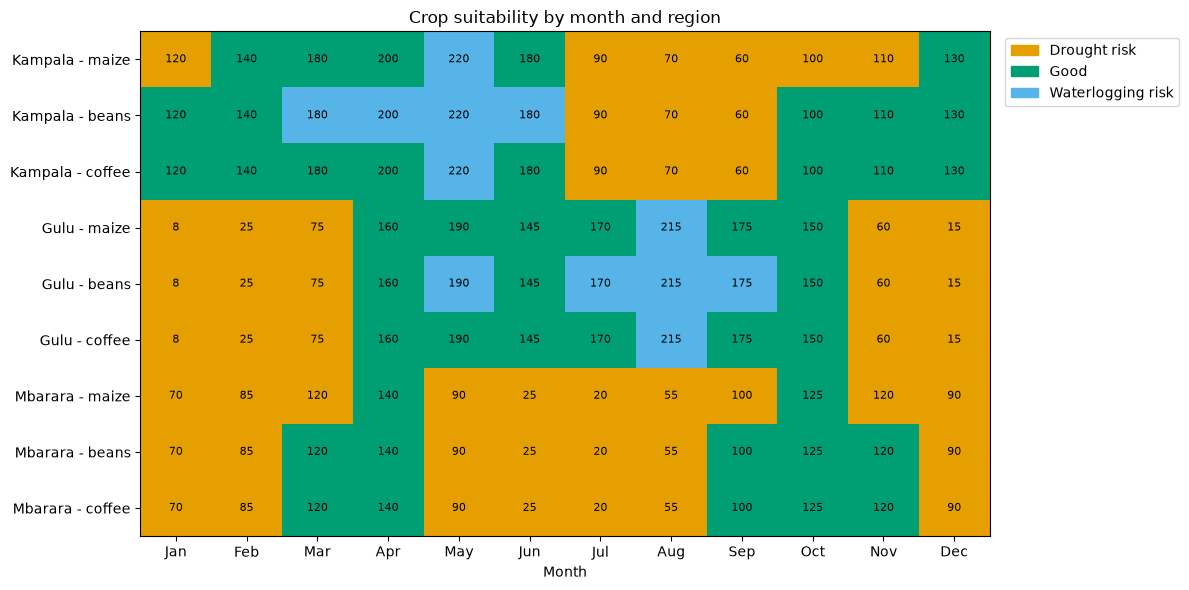

{'Kampala': {'maize': 5, 'beans': 5, 'coffee': 8}, 'Gulu': {'maize': 6, 'beans': 3, 'coffee': 6}, 'Mbarara': {'maize': 2, 'beans': 5, 'coffee': 5}}


In [8]:
code_map = {"Drought risk": 0, "Good": 1, "Waterlogging risk": 2}
rows, grid, rainfall_text = [], [], []
for r in regions:
    for rule in rules:
        rows.append(f"{r.name} - {rule.crop}")
        grid.append([code_map[s] for s in status[r.name][rule.crop]])
        rainfall_text.append(r.rainfall)
cmap = ListedColormap(["#E69F00", "#009E73", "#56B4E9"])
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(np.array(grid), cmap=cmap, vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS)
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
for i, rw in enumerate(rainfall_text):
    for j, v in enumerate(rw):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="black")
ax.set_xlabel("Month"); ax.set_title("Crop suitability by month and region")
ax.legend(handles=[Patch(color="#E69F00", label="Drought risk"), Patch(color="#009E73", label="Good"),
                   Patch(color="#56B4E9", label="Waterlogging risk")], loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig("../figures/p4_crop_heatmap.png", dpi=150); plt.show()
print({r.name: {rule.crop: status[r.name][rule.crop].count("Good") for rule in rules} for r in regions})

## Task 7: advisory note for Mbarara farmers (<= 200 words)

In [9]:
note = """**Advisory for Mbarara farmers.** Mbarara has two rainy seasons, with peaks in April and October, and a long dry spell from May to August (only 20-25 mm in June-July). Annual rain is about 1,040 mm.

**Beans are your best crop.** Rainfall sits inside the bean range (about 100-167 mm a month) in March-April and again in September-November. Plant at the start of September: September, October and November are all suitable, which covers a 3-month crop from sowing to harvest. For the first season plant in early March and expect to harvest around early June; May rain (90 mm) is slightly below the bean range, so sow promptly.

**Maize is risky.** Only April and October reach the maize range (125-200 mm). A 4-month crop will meet dry months, so grow it only with water-saving practices such as mulching, or irrigate.

**Coffee** is suitable in March-April and September-November, but total rainfall is below the 1,200 mm usually recommended, so mulch and water young trees through May-August.

*Based on illustrative rainfall data and assumed season lengths; check with UNMA forecasts before planting.*"""
n_words = len(note.replace("*", "").split())
print("word count:", n_words)
assert n_words <= 200
display(Markdown(note))

word count: 179


**Advisory for Mbarara farmers.** Mbarara has two rainy seasons, with peaks in April and October, and a long dry spell from May to August (only 20-25 mm in June-July). Annual rain is about 1,040 mm.

**Beans are your best crop.** Rainfall sits inside the bean range (about 100-167 mm a month) in March-April and again in September-November. Plant at the start of September: September, October and November are all suitable, which covers a 3-month crop from sowing to harvest. For the first season plant in early March and expect to harvest around early June; May rain (90 mm) is slightly below the bean range, so sow promptly.

**Maize is risky.** Only April and October reach the maize range (125-200 mm). A 4-month crop will meet dry months, so grow it only with water-saving practices such as mulching, or irrigate.

**Coffee** is suitable in March-April and September-November, but total rainfall is below the 1,200 mm usually recommended, so mulch and water young trees through May-August.

*Based on illustrative rainfall data and assumed season lengths; check with UNMA forecasts before planting.*

## Extension: year-to-year variability (box plots), method demonstrated on SYNTHETIC years
I did **not** have real multi-year data (NASA POWER / UNMA) in this environment, so this is **not** a real-data result. To show the method, I generated 15 synthetic years per region as `climatology x Gamma(shape=8)/8` noise (seed 2026, relative standard deviation about 35 %). Replace `years_df` with real monthly NASA POWER rainfall to get the real picture.

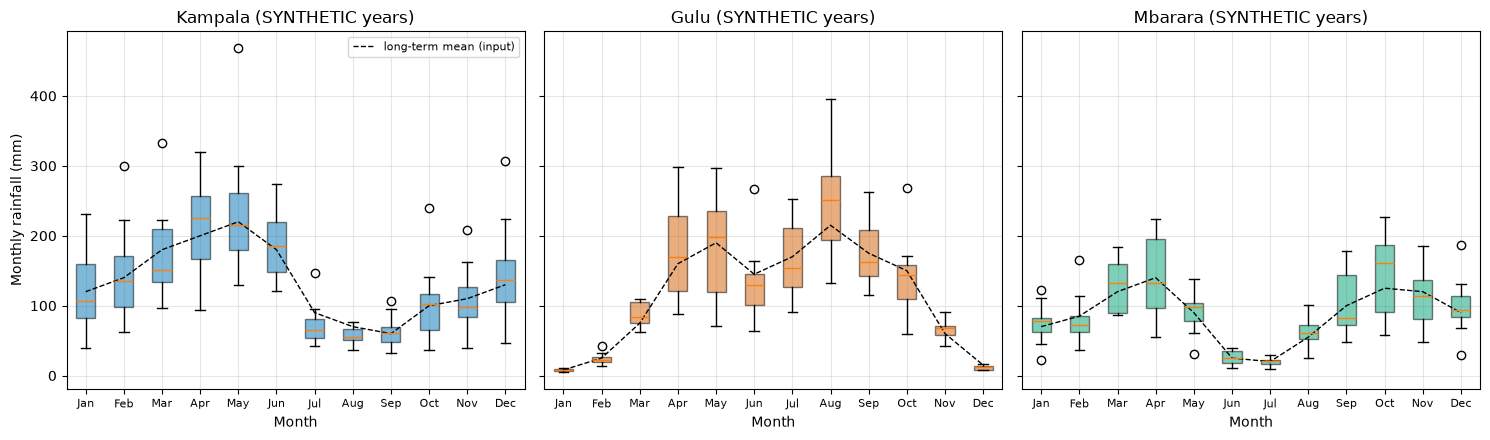

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,40%,40%,47%,20%,20%,33%,7%,0%,7%,47%,40%,47%
Gulu,0%,0%,33%,40%,27%,67%,40%,13%,60%,67%,0%,0%
Mbarara,20%,13%,47%,33%,33%,0%,0%,7%,27%,27%,60%,27%


In [10]:
rng = np.random.default_rng(2026)
N_YEARS, SHAPE = 15, 8
synthetic = {r.name: r.rainfall * rng.gamma(SHAPE, 1 / SHAPE, size=(N_YEARS, 12)) for r in regions}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, r in zip(axes, regions):
    ax.boxplot(synthetic[r.name], tick_labels=MONTHS, patch_artist=True,
               boxprops=dict(facecolor=colors[r.name], alpha=0.5))
    ax.plot(range(1, 13), r.rainfall, "k--", lw=1, label="long-term mean (input)")
    ax.set_title(f"{r.name} (SYNTHETIC years)"); ax.set_xlabel("Month"); ax.tick_params(axis="x", labelsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Monthly rainfall (mm)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("../figures/p4_boxplots_synthetic.png", dpi=150); plt.show()

# how often would the bean rule flip Good -> not Good in a given month, year to year?
beans = next(rule for rule in rules if rule.crop == "beans")
good_share = {n: np.mean([[beans.classify(v) == "Good" for v in yr] for yr in arr], axis=0) for n, arr in synthetic.items()}
display(pd.DataFrame(good_share, index=MONTHS).T.map(lambda x: f"{100*x:.0f}%"))

The last table shows the share of (synthetic) years in which each month falls in the bean range. A month that is 'Good' on average is often outside the range in individual years, which is why a single-year average climatology can overstate how reliable a planting window is.

## Findings & Limitations
**Findings.** Kampala is the wettest region (1,600 mm a year), then Gulu (1,388 mm) and Mbarara (1,040 mm). Gulu's rainfall is the most seasonal (CV 0.61, with a near-dry Dec-Feb), whereas Mbarara and Kampala have CVs of 0.43 and 0.37. Cosine similarity rates every pair as quite similar (0.75-0.89) even though Pearson correlation is near zero (-0.17 to 0.21) and Euclidean distances of 250-315 mm (root-sum-of-squares over the year) show the profiles differ a lot; the cosine score mostly reflects that rainfall is non-negative, and ignores how wet a region is, so it is the wrong tool for comparing regimes on its own. Using FAO and UCDA-derived thresholds, coffee has the most suitable months in Kampala (8), maize in Gulu (6) and beans in Kampala and Mbarara (5 each). Mbarara has only 2 maize-suitable months, so it is a bean-and-coffee region on these numbers. Peak detection finds Mbarara bimodal (Apr, Oct) and Gulu unimodal (Aug), but Kampala unimodal, contradicting its usually described two seasons.

**Limitations.** The rainfall data are illustrative single-year profiles, not climatologies, so season detection and suitability are one-year snapshots. The crop thresholds depend on my assumed season lengths and treat the upper bound as a waterlogging limit, which the sources do not state. Monthly totals hide rain intensity, distribution within the month, soil type and temperature. The peak-detection prominence threshold (25 %) is a judgement and the Kampala result is sensitive to it. The box plots use synthetic noise, so they demonstrate the method, not real variability.